# VioGén investigation · Module 2
## How a 2016 police form turned answers into a risk level, and who decided what along the way

**Research question.** Where is discretion located when the Spanish police risk form VPR4.0 (2016) converts recorded facts into an administrative risk level: with the **officer** who records the answers, with the **designers** who set weights and cut-offs, or with the **procedural rules** that attach consequences to a level?

> **Historical reconstruction only.** This is the VPR4.0 form described in a 2016 doctoral thesis. It is **not VioGén 2** (in force since 30 June 2025), not the operational police software, and it must never be used to assess a real person. Every case in this notebook is fictitious. Scores are additive units from the thesis, **not probabilities and not measures of danger**. Nothing here explains a 2025–2026 classification or a police decision.

**Primary source.** Juan José López Ossorio, *Construcción y validación de los formularios de valoración policial del riesgo de reincidencia y violencia grave contra la pareja (VPR4.0–VPER4.0)*, doctoral thesis, Universidad Autónoma de Madrid, 2016. PDF from the [UAM repository](https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content) (336 pages, MD5 `5d111ff6d9a6717d14f2c265544406f1`). Page numbers below are the thesis's printed page numbers, which equal the PDF page numbers.

**How to read the evidence labels used below**

| Label | Meaning |
|---|---|
| **DOCUMENTED** | stated in the thesis; page given |
| **INFERRED** | follows from the documented form structure, but the thesis does not state it in so many words |
| **ASSUMPTION** | a choice made by this reconstruction because the source is silent; alternatives are shown |
| **COMPUTED** | an exact calculation over the documented rule (a property of the rule, not of real cases) |

### 0 · Setup

The engine (`vpr4_historical.py`) and the verified catalogue (`vpr4_0_annex1_indicators.csv`) are embedded below, so the notebook runs on its own in Google Colab. Inside the repository, the notebook uses the script and catalogue in their respective directories and compares them with the embedded copies.

In [1]:
import hashlib, sys
from pathlib import Path

EMBEDDED = {
    'vpr4_historical.py': '"""Historical VPR4.0 scoring laboratory (López Ossorio, 2016). Version 2.\n\nEDUCATIONAL HISTORICAL RECONSTRUCTION. NOT VioGén 2. NOT the operational VioGén software. Never use it to\nassess a real person or to decide on protection.\n\nWhat is documented in the thesis (UAM, 2016) and implemented here:\n  * Annex 1, pp. 274-275: 63 weighted rows, 39 numbered indicators (I1-I39), 32 positive weights summing to 77.019.\n  * p. 193: the instrument is "de tipo actuarial con pesos aditivos ponderados"; all significant indicators add up.\n  * pp. 193-194: theoretical scale 0-77.019; empirical scale 0-68.062; cut-offs "no apreciado, de 0 hasta 9.535;\n    bajo, hasta 21.886; medio, hasta 34.715; alto, hasta 45.284; y extremo, a partir del punto anterior".\n  * Annex 2 (pp. 276-277) and Annex 5 (pp. 291-307): the form\'s structure. Sub-items are asked "en caso afirmativo"\n    (child requires parent) and several are multi-select checkboxes ("se pueden marcar varias opciones").\n  * Annex 6, Instrucción 7/2016, rule 1.5 (pp. 327-328): the system assigns the level automatically and officers may\n    raise it ("al alza"), never lower it. Rule 1.6: "no apreciado" cases may be made inactive by officers when no\n    judicial protection measure is in force.\n\nWhat is NOT documented and is a reconstruction assumption here (see METHODS_AND_LIMITATIONS.md):\n  * how the software scored "No se sabe" (unknown) answers. We never treat unknown as "No": we report the score range\n    over every possible completion of the unknown answers (lower bound = unknown counted as No, upper bound = unknown\n    counted as Sí). Because all weights are non-negative, any rule the software used lies inside that range.\n  * the exact boundary semantics at a cut-off. We read "hasta" as <=. Every cut-off can be hit exactly by some\n    consistent form (see threshold_attainability() and exact_cutoff_examples()), so the reading matters for a small\n    number of forms. At 45.284 the text itself overlaps ("alto, hasta 45.284" / "extremo, a partir del punto\n    anterior"); category(..., upper_inclusive=False) gives the alternative reading.\n"""\nfrom __future__ import annotations\n\nimport csv\nfrom dataclasses import dataclass\nfrom decimal import Decimal\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Iterable, Mapping\n\nHERE = Path(__file__).resolve().parent\n# In the standalone notebook the embedded catalogue sits beside this module.\nCATALOG_PATH = HERE.parent.parent / \'data\' / \'02_historical_scoring\' / \'vpr4_0_annex1_indicators.csv\'\nif not CATALOG_PATH.is_file():\n    CATALOG_PATH = HERE / \'vpr4_0_annex1_indicators.csv\'\nSTATUS = \'Historical VPR4.0 reconstruction (2016 thesis). Not VioGén 2; not the operational software.\'\n\nTHRESHOLD_ROWS = (  # thesis p. 194\n    (\'No appreciable risk\', Decimal(\'9.535\')),\n    (\'Low\', Decimal(\'21.886\')),\n    (\'Medium\', Decimal(\'34.715\')),\n    (\'High\', Decimal(\'45.284\')),\n    (\'Extreme\', None),\n)\nLEVEL_ES = {\'No appreciable risk\': \'No apreciado\', \'Low\': \'Bajo\', \'Medium\': \'Medio\', \'High\': \'Alto\', \'Extreme\': \'Extremo\'}\nLEVEL_ORDER = [label for label, _ in THRESHOLD_ROWS]\nTHEORETICAL_MAX = Decimal(\'77.019\')   # p. 194\nEMPIRICAL_MAX = Decimal(\'68.062\')     # p. 194: highest score observed in the construction data\n\n# Codes renamed in version 2 (the source rows carry no I-number of their own; see CHANGELOG.md)\nOLD_CODE_ALIASES = {\n    \'I5_weapons_general\': \'F02_weapons_used\',\n    \'I7_threats_general\': \'F03_threats\',\n    \'I17_criminal_history\': \'F08_criminal_record\',\n}\n\n\n@dataclass(frozen=True)\nclass Item:\n    row: int\n    page: int\n    code: str\n    indicator: str          # I-number printed for the row (\'\' for the three factor questions F02, F03, F08)\n    factor: str\n    category: int\n    spanish: str\n    english: str\n    weight: Decimal\n    parent: str\n    response_type: str\n    critical: bool\n    critical_no: int | None\n\n    @property\n    def milli(self) -> int:\n        return int(self.weight * 1000)\n\n\ndef load_items(path: Path = CATALOG_PATH) -> tuple[Item, ...]:\n    with open(path, encoding=\'utf-8-sig\', newline=\'\') as f:\n        return tuple(Item(int(r[\'row\']), int(r[\'page\']), r[\'code\'], r[\'indicator\'], r[\'factor\'], int(r[\'category\']),\n                          r[\'spanish_source_label\'], r[\'english_label\'], Decimal(r[\'weight\']), r[\'parent_code\'],\n                          r[\'response_type\'], r[\'critical_indicator\'] == \'yes\',\n                          int(r[\'critical_table1_number\']) if r[\'critical_table1_number\'] else None)\n                     for r in csv.DictReader(f))\n\n\nITEMS = load_items()\nBY_CODE = {it.code: it for it in ITEMS}\nCHILDREN: dict[str, list[str]] = {}\nfor _it in ITEMS:\n    if _it.parent:\n        CHILDREN.setdefault(_it.parent, []).append(_it.code)\nassert len(ITEMS) == 63 and len(BY_CODE) == 63\nassert sum(x.weight for x in ITEMS) == THEORETICAL_MAX\nassert all(BY_CODE[p].parent == \'\' for p in CHILDREN), \'only one level of nesting is documented\'\n\n\n# --------------------------------------------------------------------------- input handling\ndef _resolve(answers: Mapping[str, bool | None]) -> dict[str, bool | None]:\n    out: dict[str, bool | None] = {}\n    for code, value in answers.items():\n        code = OLD_CODE_ALIASES.get(code, code)\n        if code not in BY_CODE:\n            raise KeyError(f\'Unknown indicator code: {code}\')\n        if value is not True and value is not False and value is not None:\n            raise TypeError(f\'Answer {code} must be True (Sí), False (No) or None (No se sabe / not recorded)\')\n        out[code] = value\n    return out\n\n\ndef normalize(answers: Mapping[str, bool | None]) -> tuple[dict[str, bool | None], dict[str, list[str]]]:\n    """Apply the form\'s documented structure. Returns (answers for all 63 rows, notes).\n\n    * A row absent from the input is unknown (None), never "No".\n    * A sub-item answered Sí implies its parent question is Sí (sub-items are asked "en caso afirmativo").\n    * A sub-item answered Sí under a parent answered No is inconsistent and raises ValueError.\n    * When a parent is No, its sub-items are not asked: they are set to No and listed as not applicable.\n    """\n    given = _resolve(answers)\n    out: dict[str, bool | None] = {it.code: given.get(it.code) for it in ITEMS}\n    notes = {\'parent_implied\': [], \'not_applicable\': [], \'absent_from_input\': [c for c in BY_CODE if c not in given]}\n    bad = [c for c, v in out.items() if v is True and BY_CODE[c].parent and out[BY_CODE[c].parent] is False]\n    if bad:\n        raise ValueError(f\'Sub-item answered Sí while its parent question is No: {bad}\')\n    for code, v in list(out.items()):\n        p = BY_CODE[code].parent\n        if v is True and p and out[p] is not True:\n            out[p] = True\n            notes[\'parent_implied\'].append(p)\n    for parent, kids in CHILDREN.items():\n        if out[parent] is False:\n            for k in kids:\n                if out[k] is None:\n                    notes[\'not_applicable\'].append(k)\n                out[k] = False\n    return out, notes\n\n\ndef empty_case() -> dict[str, bool]:\n    """Fully specified hypothetical form with every row answered No (not an absence-of-evidence inference)."""\n    return {it.code: False for it in ITEMS}\n\n\ndef make_case(*positive_codes: str, unknown: Iterable[str] = ()) -> dict[str, bool | None]:\n    """Fully specified hypothetical form: listed codes Sí, `unknown` codes No se sabe, every other row No."""\n    case: dict[str, bool | None] = empty_case()\n    for code in positive_codes:\n        code = OLD_CODE_ALIASES.get(code, code)\n        if code not in BY_CODE:\n            raise KeyError(f\'Unknown indicator: {code}\')\n        case[code] = True\n    for code in unknown:\n        code = OLD_CODE_ALIASES.get(code, code)\n        if code not in BY_CODE:\n            raise KeyError(f\'Unknown indicator: {code}\')\n        case[code] = None\n    # parents of selected sub-items are Sí; parents of unknown sub-items cannot be No\n    for code in list(case):\n        p = BY_CODE[code].parent\n        if p and case[code] is True:\n            case[p] = True\n        elif p and case[code] is None and case[p] is False:\n            case[p] = None\n    return case\n\n\n# --------------------------------------------------------------------------- scoring\ndef category(score: Decimal | str | float, upper_inclusive: bool = True) -> str:\n    """Category for an additive score. Default reads "hasta X" (p. 194) as <= X; upper_inclusive=False gives\n    the alternative reading (a score exactly at a cut-off goes to the higher level)."""\n    val = Decimal(str(score))\n    if val < 0 or val > THEORETICAL_MAX:\n        raise ValueError(\'A VPR4.0 additive score lies between 0 and 77.019\')\n    for label, upper in THRESHOLD_ROWS:\n        if upper is None or (val <= upper if upper_inclusive else val < upper):\n            return label\n    raise AssertionError(\'unreachable\')\n\n\ndef _upper_completion(norm: Mapping[str, bool | None]) -> dict[str, bool]:\n    up = {c: (v is not False) for c, v in norm.items()}\n    for code, it in BY_CODE.items():          # a sub-item can only be Sí if its parent can be Sí\n        if it.parent and not up[it.parent]:\n            up[code] = False\n    return up\n\n\ndef evaluate(answers: Mapping[str, bool | None]) -> dict:\n    """Score a hypothetical form.\n\n    score_min / score_max bound the additive score over every completion of the unknown answers.\n    `category` is given only when nothing is unknown; `category_at_min` / `category_at_max` give the level at each\n    bound, and `category_robust_to_unknowns` says whether they agree.\n    """\n    norm, notes = normalize(answers)\n    lo = sum((BY_CODE[c].weight for c, v in norm.items() if v is True), Decimal(\'0\'))\n    up = _upper_completion(norm)\n    hi = sum((BY_CODE[c].weight for c, v in up.items() if v), Decimal(\'0\'))\n    unknown = [c for c, v in norm.items() if v is None]\n    selected = [BY_CODE[c] for c, v in norm.items() if v is True]\n    contributions = [dict(code=it.code, indicator=it.indicator or it.factor, label=it.english, weight=float(it.weight),\n                          critical=it.critical, page=it.page) for it in selected]\n    cat_lo, cat_hi = category(lo), category(hi)\n    return dict(\n        status=STATUS,\n        complete=not unknown,\n        score=float(lo), score_exact=str(lo),\n        score_min=float(lo), score_max=float(hi),\n        category=cat_lo if not unknown else None,\n        category_es=LEVEL_ES[cat_lo] if not unknown else None,\n        category_at_min=cat_lo, category_at_max=cat_hi,\n        category_robust_to_unknowns=cat_lo == cat_hi,\n        unknown_count=len(unknown), unknown_codes=unknown,\n        unknown_weight_at_stake=float(hi - lo),\n        contributions=contributions,\n        positive_rows=[c[\'code\'] for c in contributions if c[\'weight\'] > 0],\n        zero_weight_positive=[c[\'code\'] for c in contributions if c[\'weight\'] == 0],\n        indicators_present=sorted({it.indicator for it in selected if it.indicator}, key=lambda s: int(s[1:])),\n        factor_questions_yes=sorted({it.code for it in selected if not it.indicator}),\n        critical_present=[it.code for it in selected if it.critical],\n        notes=notes,\n        interpretation=(\'Historical hypothetical classification under the documented additive rule\' if not unknown else\n                        \'Some answers unknown: the category is not determined; see score_min/score_max\'),\n    )\n\n\ndef compare_cases(case_a: Mapping[str, bool | None], case_b: Mapping[str, bool | None]) -> dict:\n    a, b = evaluate(case_a), evaluate(case_b)\n    if not a[\'complete\'] or not b[\'complete\']:\n        raise ValueError(\'Comparisons require fully specified hypothetical forms\')\n    na, nb = normalize(case_a)[0], normalize(case_b)[0]\n    diffs = [dict(code=it.code, label=it.english, before=na[it.code], after=nb[it.code], weight=float(it.weight))\n             for it in ITEMS if na[it.code] != nb[it.code]]\n    return dict(before=a, after=b, delta=float(Decimal(b[\'score_exact\']) - Decimal(a[\'score_exact\'])), changes=diffs)\n\n\n# --------------------------------------------------------------------------- procedure (Instrucción 7/2016, Annex 6)\ndef apply_officer_override(automatic: str, officer_choice: str) -> dict:\n    """Rule 1.5 of Instrucción 7/2016 (thesis pp. 327-328): the level assigned automatically by VioGén "podrá ser\n    modificado por los agentes al alza" when indications not reflected in the indicators make it necessary.\n    A downward change is not provided for and is rejected."""\n    if automatic not in LEVEL_ORDER or officer_choice not in LEVEL_ORDER:\n        raise ValueError(f\'Levels must be one of {LEVEL_ORDER}\')\n    i, j = LEVEL_ORDER.index(automatic), LEVEL_ORDER.index(officer_choice)\n    if j < i:\n        raise ValueError(\'Instrucción 7/2016, rule 1.5, allows officers to change the automatic level upwards only\')\n    return dict(automatic=automatic, final=officer_choice, raised_by_officer=j > i, steps_raised=j - i,\n                rule=\'Instrucción 7/2016, rule 1.5 (thesis Annex 6, pp. 327-328)\')\n\n\ndef procedural_consequences(level: str, judicial_protection_in_force: bool | None = None) -> list[str]:\n    """What Instrucción 7/2016 (rules 1.6 and 1.8, thesis p. 328) attaches to a level. Police protection measures\n    per level are in the protocol\'s Adjunto I catalogues, which are not reproduced in the thesis."""\n    if level not in LEVEL_ORDER:\n        raise ValueError(level)\n    out = []\n    if level == \'No appreciable risk\':\n        if judicial_protection_in_force:\n            out.append(\'Rule 1.6: the case stays active because a judicial protection measure is in force.\')\n        else:\n            out.append(\'Rule 1.6: officers MAY switch the case to inactive (discretionary: "pueden"), \'\n                       \'unless a judicial protection measure is in force.\')\n    else:\n        out.append(\'Rule 1.6: the case stays active (unless e.g. death or departure abroad makes it pointless).\')\n    if level in (\'Medium\', \'High\', \'Extreme\'):\n        out.append(\'Rule 1.8: the victim is informed of the level (Ley 4/2015, Estatuto de la víctima).\')\n    out.append(\'Rule 1.8: the result is reported to the judicial authority with the main risk factors.\')\n    out.append(\'Rule 2.1: each level carries police protection measures from the Adjunto I catalogues (not in the thesis).\')\n    return out\n\n\n# --------------------------------------------------------------------------- structural analysis (exact, combinatorial)\ndef _groups() -> list[list[Item]]:\n    """Rows that must be decided together: a parent with its sub-items; rows sharing an I-number otherwise."""\n    groups: dict[str, list[Item]] = {}\n    for it in ITEMS:\n        root = it.parent or it.code\n        key = root if (root in CHILDREN) else (it.indicator or it.code)\n        groups.setdefault(key, []).append(it)\n    return list(groups.values())\n\n\ndef _facts(codes) -> tuple[set[str], set[str]]:\n    """Indicators (I1-I39) present, and \'facts\' = indicators plus factor questions (F02, F03, F08) answered Sí."""\n    inds = {BY_CODE[c].indicator for c in codes if BY_CODE[c].indicator}\n    return inds, inds | {c for c in codes if not BY_CODE[c].indicator}\n\n\ndef _group_options(group: list[Item]) -> list[tuple[int, int, int, int]]:\n    """Every consistent Sí/No assignment of a group: (milli-points, rows Sí, indicators, facts)."""\n    from itertools import product\n    opts = set()\n    for bits in product((False, True), repeat=len(group)):\n        on = {it.code for it, b in zip(group, bits) if b}\n        if any(BY_CODE[c].parent and BY_CODE[c].parent not in on for c in on):\n            continue\n        inds, facts = _facts(on)\n        opts.add((sum(BY_CODE[c].milli for c in on), len(on), len(inds), len(facts)))\n    return sorted(opts)\n\n\n@lru_cache(maxsize=None)\ndef _frontier() -> dict[int, tuple[int, ...]]:\n    """For every attainable score (milli-points): min/max rows, min/max indicators, min/max facts."""\n    state: dict[int, tuple[int, ...]] = {0: (0, 0, 0, 0, 0, 0)}\n    for g in _groups():\n        nxt: dict[int, tuple[int, ...]] = {}\n        for s, v in state.items():\n            for w, nrows, k, nf in _group_options(g):\n                cand = (v[0] + nrows, v[1] + nrows, v[2] + k, v[3] + k, v[4] + nf, v[5] + nf)\n                cur = nxt.get(s + w)\n                nxt[s + w] = cand if cur is None else tuple(min(a, b) if i % 2 == 0 else max(a, b)\n                                                            for i, (a, b) in enumerate(zip(cur, cand)))\n        state = nxt\n    return state\n\n\ndef attainable_scores() -> list[Decimal]:\n    return [Decimal(m) / 1000 for m in sorted(_frontier())]\n\n\ndef threshold_attainability() -> list[dict]:\n    """Can a consistent form score exactly a cut-off? If not, "<=" versus "<" cannot matter."""\n    f = _frontier()\n    out = []\n    for label, upper in THRESHOLD_ROWS[:-1]:\n        m = int(upper * 1000)\n        below = max(s for s in f if s <= m)\n        above = min(s for s in f if s > m)\n        out.append(dict(cutoff=str(upper), level_up_to_cutoff=label, exactly_attainable=m in f,\n                        nearest_score_below=str(Decimal(below) / 1000), nearest_score_above=str(Decimal(above) / 1000)))\n    return out\n\n\ndef category_extremes() -> list[dict]:\n    """For each level: the fewest indicators that can produce it and the most indicators it can contain."""\n    f = _frontier()\n    out = []\n    bounds = [Decimal(\'0\')] + [u for _, u in THRESHOLD_ROWS[:-1]] + [THEORETICAL_MAX]\n    for i, (label, _) in enumerate(THRESHOLD_ROWS):\n        lo_m = 0 if i == 0 else int(bounds[i] * 1000) + 1\n        hi_m = int(bounds[i + 1] * 1000)\n        inside = {s: v for s, v in f.items() if lo_m <= s <= hi_m}\n        out.append(dict(level=label, attainable_scores=len(inside),\n                        min_indicators=min(v[2] for v in inside.values()), max_indicators=max(v[3] for v in inside.values()),\n                        min_facts=min(v[4] for v in inside.values()), max_facts=max(v[5] for v in inside.values()),\n                        min_rows=min(v[0] for v in inside.values()), max_rows=max(v[1] for v in inside.values())))\n    return out\n\n\n@lru_cache(maxsize=None)\ndef _witnesses() -> dict[int, tuple[str, ...]]:\n    """One consistent form (fewest Sí rows) for every attainable score."""\n    from itertools import product\n    best: dict[int, tuple[str, ...]] = {0: ()}\n    for g in _groups():\n        nxt: dict[int, tuple[str, ...]] = {}\n        for s, codes in best.items():\n            for bits in product((False, True), repeat=len(g)):\n                on = tuple(it.code for it, b in zip(g, bits) if b)\n                if any(BY_CODE[c].parent and BY_CODE[c].parent not in on for c in on):\n                    continue\n                w = s + sum(BY_CODE[c].milli for c in on)\n                if w not in nxt or len(codes) + len(on) < len(nxt[w]):\n                    nxt[w] = codes + on\n        best = nxt\n    return best\n\n\ndef exact_cutoff_examples() -> list[dict]:\n    """A consistent hypothetical form scoring exactly each cut-off (so the boundary reading matters)."""\n    w = _witnesses()\n    out = []\n    for label, upper in THRESHOLD_ROWS[:-1]:\n        codes = w[int(upper * 1000)]\n        out.append(dict(cutoff=str(upper), codes=list(codes), inclusive_reading=category(upper),\n                        exclusive_reading=category(upper, upper_inclusive=False)))\n    return out\n\n\ndef _level_bounds_milli(level: str) -> tuple[int, int]:\n    i = LEVEL_ORDER.index(level)\n    lo = 0 if i == 0 else int(THRESHOLD_ROWS[i - 1][1] * 1000) + 1\n    up = THRESHOLD_ROWS[i][1]\n    return lo, int((up if up is not None else THEORETICAL_MAX) * 1000)\n\n\ndef indicator_count_example(level: str = \'No appreciable risk\', most: bool = True) -> dict:\n    """A concrete consistent form in `level` holding the MOST (most=True) or the FEWEST (most=False) indicators\n    I1-I39. Exact dynamic programme over the form\'s groups (indicator count is additive across groups); ties are\n    broken towards the lowest score (most=True) or the fewest rows answered Sí (most=False). Shows logical possibility under the documented form\n    structure only: it says nothing about how often, or whether, such forms occurred."""\n    from itertools import product\n    lo, hi = _level_bounds_milli(level)\n    sign = 1 if most else -1\n    best: dict[int, tuple[int, tuple[str, ...]]] = {0: (0, ())}\n    for g in _groups():\n        nxt: dict[int, tuple[int, tuple[str, ...]]] = {}\n        for s, (k, codes) in best.items():\n            for bits in product((False, True), repeat=len(g)):\n                on = tuple(it.code for it, b in zip(g, bits) if b)\n                if any(BY_CODE[c].parent and BY_CODE[c].parent not in on for c in on):\n                    continue\n                w = s + sum(BY_CODE[c].milli for c in on)\n                if w > hi:\n                    continue\n                cand = (k + len({BY_CODE[c].indicator for c in on if BY_CODE[c].indicator}), codes + on)\n                cur = nxt.get(w)\n                if cur is None or (sign * cand[0], -len(cand[1])) > (sign * cur[0], -len(cur[1])):\n                    nxt[w] = cand\n        best = nxt\n    pool = [(k, s, codes) for s, (k, codes) in best.items() if lo <= s <= hi]\n    if most:   # most indicators, then the lowest score, then fewest rows\n        k, s, codes = min(pool, key=lambda t: (-t[0], t[1], len(t[2])))\n    else:      # fewest indicators, then fewest rows, then the lowest score\n        k, s, codes = min(pool, key=lambda t: (t[0], len(t[2]), t[1]))\n    ext = next(e for e in category_extremes() if e[\'level\'] == level)\n    assert k == (ext[\'max_indicators\'] if most else ext[\'min_indicators\'])\n    ev = evaluate(make_case(*codes))\n    assert ev[\'category\'] == level\n    inds, facts = _facts(codes)\n    return dict(level=level, most=most, indicators=k, facts=len(facts), rows_yes=len(codes), codes=list(codes),\n                evaluation=ev)\n\n\ndef max_indicators_example(level: str = \'No appreciable risk\') -> dict:\n    """Kept for compatibility: the form in `level` with the most indicators (see indicator_count_example)."""\n    return indicator_count_example(level, most=True)\n\n\ndef source_integrity() -> dict:\n    w = [x.weight for x in ITEMS]\n    return dict(main_indicators=len({x.indicator for x in ITEMS if x.indicator}), item_rows=len(ITEMS),\n                factor_question_rows=sum(1 for x in ITEMS if not x.indicator), positive_rows=sum(v > 0 for v in w),\n                zero_rows=sum(v == 0 for v in w), critical_items=sum(x.critical for x in ITEMS),\n                critical_numbers=sorted(x.critical_no for x in ITEMS if x.critical),\n                theoretical_ceiling=str(sum(w)), reported_ceiling=str(THEORETICAL_MAX),\n                critical_weight_total=str(sum(x.weight for x in ITEMS if x.critical)),\n                max_attainable_under_form_structure=str(attainable_scores()[-1]))\n\n\nif __name__ == \'__main__\':\n    import json\n    print(json.dumps(source_integrity(), indent=2))\n    print(json.dumps(threshold_attainability(), indent=2))\n    print(json.dumps(category_extremes(), indent=2))\n    for label, case in [(\'Firearm\', make_case(\'I5_firearm_use\')), (\'Knife\', make_case(\'I5_knife\'))]:\n        e = evaluate(case)\n        print(label, e[\'score_exact\'], e[\'category\'])\n',
    'vpr4_0_annex1_indicators.csv': 'row,page,code,indicator,factor,factor_question_es,category,category_es,spanish_source_label,english_label,weight,weight_as_printed,parent_code,response_type,critical_indicator,critical_table1_number,structure_evidence,source,source_url\n1,274,I1_psychological,I1,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,"Violencia psicológica (vejaciones, insultos y humillaciones)","Psychological violence (humiliation, insults)",1.428,1.428,,indicator,no,,Annex 2: I01 Sí/No/No se sabe,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n2,274,I1_psychological_severe,I1,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Existencia de violencia psicológica grave o muy grave,Severe or very severe psychological violence,1.646,1.646,I1_psychological,severity_option,no,,Annex 2: severity radio Leves/Graves/Muy graves under I01; Annex 5 p.292 defines the levels,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n3,274,I2_physical,I2,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Violencia física,Physical violence,0.000,0,,indicator,no,,Annex 2: I02 Sí/No/No se sabe,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n4,274,I2_physical_injuries,I2,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Violencia física con/sin lesiones,Physical violence with or without injuries,0.000,0,I2_physical,sub_question,no,,Nested under I2 in Annex 1; no matching control is visible on the Annex 2 screen (mapping unresolved; weight 0),"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n5,274,I2_physical_severe,I2,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Existencia de violencia física grave o muy grave,Severe or very severe physical violence,2.000,2.000,I2_physical,severity_option,yes,1,Annex 2: severity radio Leve/Grave/Muy grave under I02; Annex 5 p.293,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n6,274,I3_sexual,I3,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Violencia sexual,Sexual violence,0.000,0,,indicator,no,,Annex 2: I03 Sí/No/No se sabe,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n7,274,I3_sexual_injuries,I3,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Violencia sexual con lesiones,Sexual violence with injuries,0.000,0,I3_sexual,sub_question,no,,Nested under I3 in Annex 1; no matching control visible on the Annex 2 screen (mapping unresolved; weight 0),"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n8,274,I3_sexual_severe,I3,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Existencia de violencia sexual grave o muy grave,Severe or very severe sexual violence,3.000,3.000,I3_sexual,severity_option,yes,2,Annex 2: severity radio Leve/Grave/Muy grave under I03; Annex 5 pp.293-294,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n9,274,I4_defensive_reaction,I4,F01,¿Ha existido algún tipo de violencia por parte del agresor?,1,Historia de violencia. Valoración del episodio denunciado,Reacción defensiva víctima ante agresiones físicas,Victim reacted defensively to the aggression,0.000,0,,indicator,no,,Annex 2: I04,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n10,274,F02_weapons_used,,F02,¿Ha empleado el agresor armas u objetos contra la víctima?,1,Historia de violencia. Valoración del episodio denunciado,¿Ha empleado el agresor armas u objetos contra la pareja?,Aggressor used weapons or objects against the victim (factor 2 question),1.533,1.533,,gate_question,no,,Annex 1 row without I-number above the I5 block; Annex 2: F02 Sí/No,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n11,274,I5_knife,I5,F02,¿Ha empleado el agresor armas u objetos contra la víctima?,1,Historia de violencia. Valoración del episodio denunciado,El agresor empleó arma blanca,Aggressor used a bladed weapon (knife),4.000,4.000,F02_weapons_used,subtype_checkbox,yes,3,"Annex 5 p.294: ""en caso afirmativo ... arma blanca, arma de fuego y otros objetos. Se pueden marcar varias opciones""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n12,274,I5_firearm_use,I5,F02,¿Ha empleado el agresor armas u objetos contra la víctima?,1,Historia de violencia. Valoración del episodio denunciado,El agresor empleó arma de fuego,Aggressor used a firearm,0.000,0,F02_weapons_used,subtype_checkbox,no,,Annex 5 p.294 (as row 11),"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n13,274,I5_other_object,I5,F02,¿Ha empleado el agresor armas u objetos contra la víctima?,1,Historia de violencia. Valoración del episodio denunciado,El agresor empleó otros objetos,Aggressor used other objects,0.000,0,F02_weapons_used,subtype_checkbox,no,,Annex 5 p.294 (as row 11),"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n14,274,I6_firearm_access,I6,F02,¿Ha empleado el agresor armas u objetos contra la víctima?,1,Historia de violencia. Valoración del episodio denunciado,El agresor tiene acceso a armas de fuego,Aggressor has access to firearms,0.000,0,,indicator,no,,"Annex 5 p.295: assessed ""independientemente de si empleó armas""; not conditional on F02","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n15,274,F03_threats,,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,Victim receives or has received threats or plans to cause harm (factor 3 question),0.000,0,,gate_question,no,,Annex 1 row without I-number above the I7 block; Annex 2: F03 Sí/No/No se sabe,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n16,274,I7_severe_threat,I7,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,Amenazas graves dirigidas a causar daño,Serious threats aimed at causing harm,1.893,1.893,F03_threats,severity_option,no,,Inferred to be the Graves/Muy graves options of the threat-severity radio (Annex 2; Annex 5 pp.295-296),"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n17,274,I7_suicide_threat,I7,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,Amenazas de suicidio por parte del agresor,Aggressor threatens suicide,2.049,2.049,F03_threats,subtype_checkbox,no,,"Annex 5 p.295: ""En caso de existir amenazas ... Se pueden marcar varias opciones""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n18,274,I7_economic_threat,I7,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,Amenazas económicas por parte del agresor,Economic threats by the aggressor,0.000,0,F03_threats,subtype_checkbox,no,,Annex 5 p.295,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n19,274,I7_death_threat,I7,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,Amenazas de muerte por parte del agresor,Death threats by the aggressor,2.800,2.800,F03_threats,subtype_checkbox,yes,4,Annex 5 p.295,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n20,274,I7_reputation_threat,I7,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,Amenazas a la reputación social de la víctima por parte del agresor,Threats to the victim\'s social reputation,0.000,0,F03_threats,subtype_checkbox,no,,Annex 5 p.295,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n21,274,I7_children_threat,I7,F03,¿La víctima recibe o ha recibido amenazas o planes dirigidos a causar daño físico/psicológico?,1,Historia de violencia. Valoración del episodio denunciado,Amenazas a la integridad/custodia de los hijos,Threats to the integrity or custody of the children,0.000,0,F03_threats,subtype_checkbox,no,,Annex 5 p.295,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n22,274,I8_escalation,I8,F04,¿Ha existido una escalada en la gravedad y/o la frecuencia de las agresiones o las amenazas de violencia en los últimos seis meses?,1,Historia de violencia. Valoración del episodio denunciado,¿Ha existido una escalada en la gravedad y/o la frecuencia de las agresiones o las amenazas de violencia en los últimos seis meses?,Escalation in severity and/or frequency in the last six months,2.800,2.800,,indicator,yes,5,Annex 5 p.296: factor 4 = indicator 8,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n23,274,I9_jealousy,I9,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra celos exagerados o sospechas de infidelidad,Exaggerated jealousy or suspicion of infidelity (last 6 months),3.540,3.540,,indicator,yes,6,Annex 2: I09 under F05,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n24,274,I10_control_general,I10,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra conductas de control,Controlling behaviour (last 6 months),2.184,2.184,,indicator,no,,Annex 2: I10 under F05,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n25,274,I10_control_physical,I10,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra conductas de control físico,Physical control (limits movement),1.689,1.689,I10_control_general,subtype_checkbox,no,,"Annex 5 p.297: ""En caso afirmativo ... permitiéndose señalar distintas opciones""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n26,274,I10_control_psychological,I10,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra conductas de control psicológico,Psychological and/or social control,1.665,1.665,I10_control_general,subtype_checkbox,no,,Annex 5 pp.297-298,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n27,274,I10_control_work,I10,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra conductas de control escolar/laboral,School or work control,2.087,2.087,I10_control_general,subtype_checkbox,no,,Annex 5 p.298,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n28,274,I10_control_economic,I10,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra conductas de control económico,Economic control,0.000,0,I10_control_general,subtype_checkbox,no,,Annex 5 p.298,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n29,274,I10_control_cyber,I10,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra conductas de control cibernético,"Cyber control (social media, messages, calls)",1.578,1.578,I10_control_general,subtype_checkbox,no,,Annex 5 p.298,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 274",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n30,275,I11_stalking,I11,F05,"Celos exagerados, control y acoso, en los últimos seis meses",1,Historia de violencia. Valoración del episodio denunciado,En los últimos 6 meses el agresor muestra acoso,Stalking or harassment (last 6 months),4.940,4.940,,indicator,yes,7,Annex 2: I11 under F05,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n31,275,I12_material_damage,I12,F06,¿Ha mostrado el agresor alguno de estos comportamientos en el último año?,2,Factores e indicadores relacionados con el agresor,En el último año el agresor produce daños materiales,Property damage (last year),0.000,0,,indicator,no,,Annex 2: I12 under F06,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n32,275,I13_disrespect_authority,I13,F06,¿Ha mostrado el agresor alguno de estos comportamientos en el último año?,2,Factores e indicadores relacionados con el agresor,En el último año el agresor falta respeto a la autoridad,Disrespect for authority (last year),1.892,1.892,,indicator,no,,Annex 2: I13,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n33,275,I14_attack_others_animals,I14,F06,¿Ha mostrado el agresor alguno de estos comportamientos en el último año?,2,Factores e indicadores relacionados con el agresor,En el último año agrede físicamente a terceros y/o animales,Physically attacks third parties and/or animals (last year),3.830,3.830,,indicator,yes,8,Annex 2: I14,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n34,275,I15_confrontation_others,I15,F06,¿Ha mostrado el agresor alguno de estos comportamientos en el último año?,2,Factores e indicadores relacionados con el agresor,En el último año existen enfrentamientos físicos o verbales con terceras personas,Physical or verbal confrontations with third parties (last year),1.466,1.466,,indicator,no,,Annex 2: I15,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n35,275,I16_problems_general,I16,F07,"En los últimos seis meses, ¿existen indicios de problemas en la vida del agresor?",2,Factores e indicadores relacionados con el agresor,"En los últimos seis meses, ¿existen indicios de problemas en la vida del agresor?",Signs of problems in the aggressor\'s life (last 6 months),1.628,1.628,,indicator,no,,"Annex 5 p.301: factor 7 ""corresponde con el Indicador 16""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n36,275,I16_work_economic_problems,I16,F07,"En los últimos seis meses, ¿existen indicios de problemas en la vida del agresor?",2,Factores e indicadores relacionados con el agresor,Existencia de problemas laborales/económicos del agresor en los últimos 6 meses,Work or economic problems (last 6 months),0.000,0,I16_problems_general,subtype_checkbox,no,,"Annex 5 p.301: ""en caso de existir ... se deberá concretar el tipo ... Se permite marcar varias opciones""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n37,275,I16_legal_problems,I16,F07,"En los últimos seis meses, ¿existen indicios de problemas en la vida del agresor?",2,Factores e indicadores relacionados con el agresor,Existencia de problemas del agresor con la justicia en los últimos 6 meses,Problems with the justice system (last 6 months),0.000,0,I16_problems_general,subtype_checkbox,no,,Annex 5 p.301,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n38,275,F08_criminal_record,,F08,¿El agresor tiene antecedentes penales y/o policiales?,2,Factores e indicadores relacionados con el agresor,Existen antecedentes penales/policiales del agresor,Aggressor has a criminal and/or police record (factor 8 question),2.142,2.142,,gate_question,no,,Annex 1 row without I-number above I17-I19; Annex 2: F08 Sí/No,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n39,275,I17_prior_breaches,I17,F08,¿El agresor tiene antecedentes penales y/o policiales?,2,Factores e indicadores relacionados con el agresor,Existen quebrantamientos previos (cautelares/penales),Previous breaches of precautionary or criminal measures,2.336,2.336,F08_criminal_record,indicator,no,,"Annex 5 p.301: ""en caso afirmativo, se debe especificar si existen quebrantamientos previos ... (Indicador 17)""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n40,275,I18_prior_aggression,I18,F08,¿El agresor tiene antecedentes penales y/o policiales?,2,Factores e indicadores relacionados con el agresor,Existen antecedentes de agresiones físicas/sexuales,Record of physical and/or sexual aggression against others,1.870,1.870,F08_criminal_record,indicator,no,,"Annex 5 p.301: ""... antecedentes por agresiones físicas y/o sexuales a terceras personas (Indicador 18)""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n41,275,I19_prior_ipv_other_partners,I19,F08,¿El agresor tiene antecedentes penales y/o policiales?,2,Factores e indicadores relacionados con el agresor,Existen antecedentes de violencia de género sobre otras parejas,Record of gender violence against other partners,1.571,1.571,F08_criminal_record,indicator,no,,"Annex 5 p.301: ""... antecedentes de violencia de género sobre otra/s víctima/s (Indicador 19)""","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n42,275,I20_mental_disorder,I20,F09,¿Se da alguna de las siguientes circunstancias en el agresor?,2,Factores e indicadores relacionados con el agresor,El agresor presenta un trastorno mental/psiquiátrico,Aggressor has a diagnosed mental/psychiatric disorder,3.000,3.000,,indicator,yes,9,"p.192: weight fixed at 3 (""puntuación directa de 3"")","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n43,275,I21_suicide_ideation,I21,F09,¿Se da alguna de las siguientes circunstancias en el agresor?,2,Factores e indicadores relacionados con el agresor,El agresor presenta ideas/intentos de suicidio,Aggressor shows suicidal ideas or attempts,3.890,3.890,,indicator,yes,10,Annex 2: I21,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n44,275,I22_substance_abuse,I22,F09,¿Se da alguna de las siguientes circunstancias en el agresor?,2,Factores e indicadores relacionados con el agresor,"El agresor mantiene algún tipo adicción o conductas de abuso (alcohol, drogas y fármacos)",Aggressor has an addiction or substance abuse,3.336,3.336,,indicator,yes,11,Annex 2: I22,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n45,275,I23_family_history,I23,F09,¿Se da alguna de las siguientes circunstancias en el agresor?,2,Factores e indicadores relacionados con el agresor,El agresor tiene antecedentes familiares de violencia de género o doméstica,Family history of gender or domestic violence (aggressor),1.667,1.667,,indicator,no,,Annex 2: I23,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n46,275,I24_disability,I24,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Existencia de algún tipo de discapacidad,Victim has a disability,0.000,0,,indicator,no,,Annex 2: I24,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n47,275,I25_pregnancy,I25,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Víctima en periodo de gestación,Victim is pregnant,0.000,0,,indicator,no,,Annex 2: I25,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n48,275,I26_serious_illness,I26,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Víctima con enfermedad grave,Victim has a serious illness,0.000,0,,indicator,no,,Annex 2: I26,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n49,275,I27_foreign,I27,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Víctima extranjera,Victim is a foreign national,0.000,0,,indicator,no,,Annex 2: I27,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n50,275,I28_social_support,I28,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Víctima sin apoyo familiar/social,Victim lacks family or social support,0.000,0,,indicator,no,,Annex 2: I28,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n51,275,I29_mental_disorder,I29,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Víctima con trastorno mental/psiquiátrico,Victim has a diagnosed mental/psychiatric disorder,0.000,0,,indicator,no,,Annex 2: I29,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n52,275,I30_suicidal,I30,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,Víctima con ideas/intentos de suicidio,Victim shows suicidal ideas or attempts,0.000,0,,indicator,no,,Annex 2: I30,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n53,275,I31_substance_abuse,I31,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,"La víctima mantiene algún tipo adicción o conductas de abuso (alcohol, drogas y fármacos)",Victim has an addiction or substance abuse,0.000,0,,indicator,no,,Annex 2: I31,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n54,275,I32_prior_ipv,I32,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima tiene antecedentes de violencia de género o doméstica,Victim has a history of gender or domestic violence,0.000,0,,indicator,no,,"Annex 5 p.304: two options, ""Se permite marcar las dos opciones""; exact row-to-checkbox mapping unresolved","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n55,275,I32_family_ipv,I32,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima tiene antecedentes familiares de violencia de género o doméstica,Victim has a family history of gender or domestic violence,0.000,0,,subtype_checkbox,no,,Annex 5 p.304 (as row 54),"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n56,275,I33_economic_dependence,I33,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima depende económicamente del agresor,Victim depends economically on the aggressor,0.000,0,,indicator,no,,Annex 2: I33,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n57,275,I34_dependents,I34,F10,¿Se da alguna de las siguientes circunstancias de vulnerabilidad en la víctima?,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima tiene a su cargo menores de edad o familiares,Victim cares for minors or dependent relatives,0.000,0,,indicator,no,,Annex 2: I34,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n58,275,I35_prior_reports,I35,F11,Circunstancias agravantes,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima ha denunciado a otros agresores en el pasado,Victim has reported other aggressors in the past,0.000,0,,indicator,no,,Annex 2: I35,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n59,275,I35_withdrawn_reports,I35,F11,Circunstancias agravantes,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima ha retirado denuncias en el pasado,Victim has withdrawn reports in the past,0.000,0,,sub_question,no,,"Annex 5 p.305: also covers reports against the current aggressor; ""Se pueden marcar ambos"" (not conditional)","López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n60,275,I36_recent_separation,I36,F11,Circunstancias agravantes,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima ha expresado al agresor su intención de romper hace menos de 6 meses,Victim told the aggressor she intends to end the relationship (last 6 months),3.286,3.286,,indicator,yes,12,Annex 2: I36,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n61,275,I37_reciprocal,I37,F11,Circunstancias agravantes,3,Vulnerabilidad de la víctima y calidad de la relación,Se han registrado episodios de violencia recíproca,Episodes of reciprocal violence recorded,0.000,0,,indicator,no,,Annex 5 p.306: never asked literally; the officer must infer it,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n62,275,I38_family_fear,I38,F11,Circunstancias agravantes,3,Vulnerabilidad de la víctima y calidad de la relación,La víctima teme por la integridad de los menores o familiares a su cargo,Victim fears for the minors or relatives in her care,1.443,1.443,,indicator,no,,Annex 2: I38,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n63,275,I39_victim_fear_lethal,I39,F12,La mujer piensa que el agresor es capaz de agredirla con mucha violencia o incluso matarla,4,Percepción de la víctima sobre su situación,La víctima piensa que el agresor es capaz de agredirla con mucha violencia o incluso matarla,Victim thinks the aggressor could seriously harm or even kill her,2.830,2.830,,indicator,yes,13,Annex 2: F12 / I39,"López Ossorio (2016), doctoral thesis, UAM, Annex 1, p. 275",https://repositorio.uam.es/server/api/core/bitstreams/09c11ef0-a544-439a-a623-4e492db41610/content\n',
}
EMBEDDED_SHA256 = {'vpr4_historical.py': 'ef11fa51a0976845a4f8e301ba6b3d536ca82345cbb32b9e2e734802c980c87b', 'vpr4_0_annex1_indicators.csv': '69dc7c6cd060b0b5adbe732c10e3464aa1b3bf8bde9b883b30468a9da3e965a1'}

cwd = Path.cwd()
script_dir = Path('scripts/02_historical_scoring')
repo = next((p for p in (cwd, *cwd.parents) if (p / script_dir / 'vpr4_historical.py').is_file()), None)
base = repo / script_dir if repo is not None else cwd
data_dir = repo / 'data' / '02_historical_scoring' if repo is not None else cwd
for name, text in EMBEDDED.items():
    path = (data_dir if name.endswith('.csv') else base) / name
    if not path.exists():
        path.write_text(text, encoding='utf-8', newline='')
        print(f'{name}: written from the embedded copy')
    else:
        same = hashlib.sha256(path.read_text(encoding='utf-8').encode('utf-8')).hexdigest() == EMBEDDED_SHA256[name]
        print(f'{name}: local file used; {"identical to" if same else "DIFFERENT FROM"} the embedded copy')
if str(base) not in sys.path:
    sys.path.insert(0, str(base))

import pandas as pd
import matplotlib.pyplot as plt
import vpr4_historical as V
from vpr4_historical import ITEMS, BY_CODE, CHILDREN, THRESHOLD_ROWS, LEVEL_ORDER, evaluate, make_case, compare_cases

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 160)
SURF, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE = '#2a78d6', '#eb6834'
RAMP = ['#cde2fb', '#86b6ef', '#5598e7', '#256abf', '#104281']
plt.rcParams.update({'font.size': 9.5, 'axes.edgecolor': GRID, 'axes.facecolor': SURF, 'figure.facecolor': SURF,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.grid': True, 'grid.color': GRID})
catalog = pd.read_csv(data_dir / 'vpr4_0_annex1_indicators.csv', dtype=str, keep_default_na=False)
catalog['w'] = catalog['weight'].astype(float)
print(V.STATUS)

vpr4_historical.py: local file used; identical to the embedded copy
vpr4_0_annex1_indicators.csv: local file used; identical to the embedded copy
Historical VPR4.0 reconstruction (2016 thesis). Not VioGén 2; not the operational software.


### 1 · Is the table right? Verifying the transcription against the thesis

Annex 1 (pp. 274–275) prints 63 rows: 39 numbered indicators (I1–I39), some with sub-items, and three rows with **no indicator number** (the gate questions of factors 2, 3 and 8). Each row has one value in the column headed "Odds ratio", which is the additive weight.

**What was checked, row by row.** Every row was typed by hand from the page images (`tools/annex1_transcription.py`). An automatic check then confirms that each Spanish label occurs in the PDF text of its page and that the sequence of 63 values read from the right-hand column of the PDF equals the transcription. Critical flags were checked against Table 1 (p. 193), cut-offs against p. 194, and the form structure against Annexes 2 and 5. Every claim and its status is listed in `SOURCE_VERIFICATION_MATRIX.csv`.

**Why the 77.019 total is not proof.** The weights add up to the thesis's stated maximum, but that only shows the *multiset* of numbers is right. A weight attached to the wrong row, a mislabelled row, or a wrong parent leaves the total unchanged:

In [2]:
info = V.source_integrity()
print({k: info[k] for k in ['main_indicators', 'item_rows', 'factor_question_rows', 'positive_rows', 'zero_rows',
                            'critical_items', 'theoretical_ceiling', 'critical_weight_total']})

# A transposition error that the total cannot detect: swap the knife and firearm weights
swapped = catalog['w'].copy()
i_knife = catalog.index[catalog.code == 'I5_knife'][0]; i_fire = catalog.index[catalog.code == 'I5_firearm_use'][0]
swapped[i_knife], swapped[i_fire] = swapped[i_fire], swapped[i_knife]
print(f"\nTotal with the correct table: {catalog['w'].sum():.3f}")
print(f"Total with knife and firearm weights swapped: {swapped.sum():.3f}  <- identical, yet every weapon example would change")

{'main_indicators': 39, 'item_rows': 63, 'factor_question_rows': 3, 'positive_rows': 32, 'zero_rows': 31, 'critical_items': 13, 'theoretical_ceiling': '77.019', 'critical_weight_total': '43.252'}

Total with the correct table: 77.019
Total with knife and firearm weights swapped: 77.019  <- identical, yet every weapon example would change


**What the verification changed** (version 1 → version 2; details in `CHANGELOG.md`). The weights themselves were all correct. The structure was not:

In [3]:
corrections = pd.DataFrame([
    ('10, 15, 38', 'Rows had been given the numbers I5, I7 and I17', 'The source prints no indicator number: they are the gate questions of factors 2, 3 and 8. Renamed F02_weapons_used, F03_threats, F08_criminal_record (old codes still accepted).'),
    ('38 → 39', 'Row 38 ("has a criminal and/or police record") was labelled I17', 'I17 is row 39, "previous breaches of measures". Row 38 is the factor-8 question.'),
    ('40, 41', 'I18 and I19 had no parent', 'Annex 5 p. 301: asked only "en caso afirmativo" to the record question. I18 alone now scores 2.142 + 1.870 = 4.012 (was 1.870).'),
    ('18, 20', 'Spanish labels truncated', 'Restored "... por parte del agresor".'),
    ('all', 'Invented thematic "sections"', 'Replaced by the source factors F01–F12 and the four categories of the form (Annex 2).'),
], columns=['Annex 1 row(s)', 'Version 1', 'Version 2 (verified)'])
corrections

,Annex 1 row(s),Version 1,Version 2 (verified)
0,"10, 15, 38","Rows had been given the numbers I5, I7 and I17","The source prints no indicator number: they are the gate questions of factors 2, 3 and..."
1,38 → 39,"Row 38 (""has a criminal and/or police record"") was labelled I17","I17 is row 39, ""previous breaches of measures"". Row 38 is the factor-8 question."
2,"40, 41",I18 and I19 had no parent,"Annex 5 p. 301: asked only ""en caso afirmativo"" to the record question. I18 alone now ..."
3,"18, 20",Spanish labels truncated,"Restored ""... por parte del agresor""."
4,all,"Invented thematic ""sections""",Replaced by the source factors F01–F12 and the four categories of the form (Annex 2).


### 2 · How the form is structured: additive, dependent, or mutually exclusive?

* **DOCUMENTED (p. 193).** The instrument is "de tipo actuarial con pesos aditivos ponderados": weights of the items answered *Sí* are added.
* **DOCUMENTED (Annex 5).** Sub-items are asked only "en caso afirmativo" (a child requires its parent). Weapon types (p. 294), threat types (p. 295), control types (p. 297) and life-problem types (p. 301) are checkboxes: "se pueden marcar varias opciones". Firearm *access* (I6) is assessed "independientemente de si empleó armas" (p. 295), so it is not a sub-item of weapon use. I17–I19 are asked only if the record question (F08) is *Sí* (p. 301).
* **DOCUMENTED (Annex 2).** Severity is a radio button *Leve / Grave / Muy grave*. Annex 1 has one row "grave o muy grave"; choosing *Leve* adds nothing.
* **INFERRED.** The only mutually exclusive choice on the screen (the severity radio) has a single weighted option, so **no two weighted rows exclude each other**. The full 77.019 is therefore attainable by a consistent form; the highest score observed in the construction sample was 68.062 (p. 194).

In [4]:
types = (catalog.groupby('response_type')
         .agg(rows=('code', 'size'), weighted_rows=('w', lambda s: int((s > 0).sum())), points=('w', 'sum'))
         .reindex(['indicator', 'gate_question', 'severity_option', 'subtype_checkbox', 'sub_question']))
types['how it combines'] = ['added if Sí (I17-I19 only when F08 is Sí)',
                            'added if Sí; opens its sub-items',
                            'added if the radio is Grave or Muy grave (needs its parent)',
                            'added for each box ticked (needs its parent)',
                            'added if Sí (needs its parent)']
display(types.round(3))
parents = pd.DataFrame([(p, BY_CODE[p].weight, ', '.join(f'{c} ({BY_CODE[c].weight})' for c in kids))
                        for p, kids in CHILDREN.items()], columns=['parent row', 'parent weight', 'sub-items (weight)'])
display(parents)
full = evaluate(make_case(*BY_CODE))
print('Every row Sí, consistent with the structure:', full['score_exact'], full['category'])

,rows,weighted_rows,points,how it combines
response_type,,,,
indicator,37,19,48.937,added if Sí (I17-I19 only when F08 is Sí)
gate_question,3,2,3.675,added if Sí; opens its sub-items
severity_option,4,4,8.539,added if the radio is Grave or Muy grave (needs its parent)
subtype_checkbox,16,7,15.868,added for each box ticked (needs its parent)
sub_question,3,0,0.000,added if Sí (needs its parent)


,parent row,parent weight,sub-items (weight)
0,I1_psychological,1.428,I1_psychological_severe (1.646)
1,I2_physical,0.000,"I2_physical_injuries (0.000), I2_physical_severe (2.000)"
2,I3_sexual,0.000,"I3_sexual_injuries (0.000), I3_sexual_severe (3.000)"
3,F02_weapons_used,1.533,"I5_knife (4.000), I5_firearm_use (0.000), I5_other_object (0.000)"
4,F03_threats,0.000,"I7_severe_threat (1.893), I7_suicide_threat (2.049), I7_economic_threat (0.000), I7_de..."
5,I10_control_general,2.184,"I10_control_physical (1.689), I10_control_psychological (1.665), I10_control_work (2.0..."
6,I16_problems_general,1.628,"I16_work_economic_problems (0.000), I16_legal_problems (0.000)"
7,F08_criminal_record,2.142,"I17_prior_breaches (2.336), I18_prior_aggression (1.870), I19_prior_ipv_other_partners..."


Every row Sí, consistent with the structure: 77.019 Extreme


### 3 · From score to level: where the designers drew the lines

**DOCUMENTED (p. 194).** "no apreciado, de 0 hasta 9.535; bajo, hasta 21.886; medio, hasta 34.715; alto, hasta 45.284; y extremo, a partir del punto anterior". The cut-offs were chosen with three criteria: a low share of **false negatives** at the first cut-off "aunque aumentase la tasa de falsos positivos"; levels from *medio* upwards should capture most of the cases considered most serious; and, "en menor grado", proportions per level that are "asumibles desde el punto de vista de la seguridad", meaning workable for police resources. The last criterion is an administrative one, written into a numerical threshold.

**ASSUMPTION.** The text does not say whether "hasta" includes the cut-off, and at 45.284 it overlaps ("alto, hasta 45.284" / "extremo, a partir del punto anterior"). We read "hasta" as ≤. **COMPUTED:** every cut-off can be hit *exactly* by a consistent form, so the reading changes the level of some forms:

In [5]:
att = pd.DataFrame(V.threshold_attainability())
ex = pd.DataFrame(V.exact_cutoff_examples())
att['example form scoring exactly the cut-off'] = ex['codes'].apply(', '.join)
att['level if "hasta" is inclusive'] = ex['inclusive_reading']
att['level if exclusive'] = ex['exclusive_reading']
att[['cutoff', 'exactly_attainable', 'level if "hasta" is inclusive', 'level if exclusive', 'example form scoring exactly the cut-off']]

,cutoff,exactly_attainable,"level if ""hasta"" is inclusive",level if exclusive,example form scoring exactly the cut-off
0,9.535,True,No appreciable risk,Low,"I10_control_general, I10_control_physical, I13_disrespect_authority, I16_problems_gene..."
1,21.886,True,Low,Medium,"I11_stalking, I14_attack_others_animals, I21_suicide_ideation, I23_family_history, I36..."
2,34.715,True,Medium,High,"F02_weapons_used, I5_knife, I8_escalation, I10_control_general, I10_control_work, I11_..."
3,45.284,True,High,Extreme,"F02_weapons_used, I5_knife, F03_threats, I7_death_threat, I8_escalation, I9_jealousy, ..."


### 4 · Firearm versus knife: what the numbers say, and what they do not

Both start from the weapon-use question F02 (1.533). The knife box adds 4.000 because "empleo de arma blanca" is one of the 13 **critical indicators**: chosen "con ponderación experta para un screening del riesgo de homicidio", with the consensus of three clinical and forensic experts, and doubled ("el peso final ... se obtuvo multiplicando por 2 su valor inicial", pp. 191–193). Firearm use is not on that list, and the thesis does not say why. The firearm box adds 0.

Where the empirical weights come from. **DOCUMENTED.** The Annex 1 weights are odds ratios for *reincidencia policial*, a new report against the same aggressor, within **four months** (p. 191), estimated on 60% of a cohort of 6,613 cases reported in autumn 2015 (n = 3,907). In the thesis's study of the predecessor form VPR2015 (Table 1, p. 163; criterion: a new report within six months), firearm use appeared in **30 of 6,613 cases** and its association was not significant (RR 1.408, 95% CI 0.479–4.134); knife use was significant (RR 1.845, p < .001). A rare item cannot reach significance in that design. The zero is therefore **a property of the sample and of the criterion** (a new police report within months, not lethality). It says nothing about how dangerous firearms are.

In [6]:
rows = []
for label, codes in [('Firearm used', ['I5_firearm_use']), ('Knife used', ['I5_knife']),
                     ('Firearm and knife used', ['I5_firearm_use', 'I5_knife']), ('Access to firearms, no use', ['I6_firearm_access'])]:
    e = evaluate(make_case(*codes))
    rows.append((label, ' + '.join(f"{c['indicator']} {c['weight']:.3f}" for c in e['contributions']), e['score_exact'], e['category']))
pd.DataFrame(rows, columns=['fictitious form (every other row No)', 'contributions', 'score', 'historical level'])

,fictitious form (every other row No),contributions,score,historical level
0,Firearm used,F02 1.533 + I5 0.000,1.533,No appreciable risk
1,Knife used,F02 1.533 + I5 4.000,5.533,No appreciable risk
2,Firearm and knife used,F02 1.533 + I5 4.000 + I5 0.000,5.533,No appreciable risk
3,"Access to firearms, no use",I6 0.000,0.000,No appreciable risk


### 5 · Thirty-one rows that are recorded but weigh nothing

**DOCUMENTED (p. 196).** Only indicators with empirical weight contribute to the scale; "el resto se van a mantener durante un periodo estimado de unos 18 meses con la finalidad de obtener más información sobre ellos". A weight of zero is a **design decision about what counts** for the score. It does not mean that the circumstance is harmless, and the officer still records it.

Almost all of the victim-vulnerability block (category 3) is in that position: disability, pregnancy, serious illness, being foreign, lack of support, dependent children, economic dependence.

In [7]:
z = catalog.assign(weighted=catalog.w > 0).groupby(['category', 'category_es'])['weighted'].agg(rows='size', weighted='sum')
z['zero_weight'] = z['rows'] - z['weighted']
display(z)
e = evaluate(make_case('I24_disability', 'I25_pregnancy', 'I26_serious_illness', 'I28_social_support', 'I33_economic_dependence', 'I34_dependents'))
print('Six vulnerability facts answered Sí ->', e['score_exact'], e['category'], '| zero-weight rows Sí:', len(e['zero_weight_positive']))

,,rows,weighted,zero_weight
category,category_es,,,
1,Historia de violencia. Valoración del episodio denunciado,30,17,13
2,Factores e indicadores relacionados con el agresor,15,12,3
3,Vulnerabilidad de la víctima y calidad de la relación,17,2,15
4,Percepción de la víctima sobre su situación,1,1,0


Six vulnerability facts answered Sí -> 0.000 No appreciable risk | zero-weight rows Sí: 6


### 6 · Can a form record many indicators and still score "no apreciado"?

The thesis says a level can be reached "mediante la suma de muchos indicadores con peso bajo y, también con la suma de menos indicadores de mayor peso" (p. 192). **COMPUTED:** we enumerated exactly (by dynamic programming over the form's groups, respecting every parent–child rule) the fewest and the most indicators a consistent form can hold in each level. "Facts" adds the three weighted gate questions (F02, F03, F08), which have no I-number.

This establishes what is **logically possible under the rule**. It does not say such forms occurred, and it says nothing about the danger in any real situation.

,level,min_indicators,max_indicators,min_facts,max_facts,attainable_scores
0,No appreciable risk,0,25,0,27,3130
1,Low,1,30,2,33,12350
2,Medium,3,34,5,37,12829
3,High,6,37,8,40,10569
4,Extreme,9,39,12,42,26001


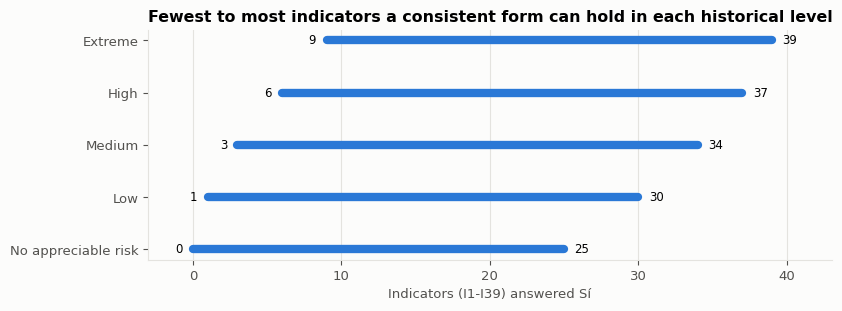

In [8]:
ext = pd.DataFrame(V.category_extremes())[['level', 'min_indicators', 'max_indicators', 'min_facts', 'max_facts', 'attainable_scores']]
display(ext)
fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, r in ext.iterrows():
    ax.plot([r.min_indicators, r.max_indicators], [i, i], color=BLUE, lw=6, solid_capstyle='round')
    ax.text(r.min_indicators - 0.7, i, str(r.min_indicators), ha='right', va='center', fontsize=8.5)
    ax.text(r.max_indicators + 0.7, i, str(r.max_indicators), ha='left', va='center', fontsize=8.5)
ax.set_yticks(range(len(ext))); ax.set_yticklabels(ext.level); ax.grid(axis='y', visible=False)
ax.set_xlim(-3, 43); ax.set_xlabel('Indicators (I1-I39) answered Sí')
ax.set_title('Fewest to most indicators a consistent form can hold in each historical level')
plt.tight_layout(); plt.show()

In [9]:
most = V.indicator_count_example('No appreciable risk', most=True)
print(f"MOST indicators while 'No apreciado': {most['indicators']} indicators ({most['facts']} facts), score {most['evaluation']['score_exact']}")
display(pd.DataFrame(most['evaluation']['contributions'])[['indicator', 'label', 'weight']])
few = V.indicator_count_example('Extreme', most=False)
print(f"FEWEST indicators for 'Extremo': {few['indicators']} indicators ({few['facts']} facts), score {few['evaluation']['score_exact']}")
print(', '.join(few['codes']))

MOST indicators while 'No apreciado': 25 indicators (27 facts), score 9.165


,indicator,label,weight
0,I1,"Psychological violence (humiliation, insults)",1.428
1,I2,Physical violence,0.000
2,I3,Sexual violence,0.000
3,I4,Victim reacted defensively to the aggression,0.000
4,F02,Aggressor used weapons or objects against the victim (factor 2 question),1.533
5,I5,Aggressor used other objects,0.000
6,I6,Aggressor has access to firearms,0.000
7,F03,Victim receives or has received threats or plans to cause harm (factor 3 question),0.000
8,I7,Threats to the integrity or custody of the children,0.000
9,I12,Property damage (last year),0.000


FEWEST indicators for 'Extremo': 9 indicators (12 facts), score 45.352
F02_weapons_used, I5_knife, F03_threats, I7_severe_threat, I7_suicide_threat, I7_death_threat, I8_escalation, I9_jealousy, I10_control_general, I10_control_physical, I10_control_psychological, I10_control_work, I10_control_cyber, I11_stalking, I14_attack_others_animals, F08_criminal_record, I22_substance_abuse, I36_recent_separation


Read the first table carefully: physical violence, sexual violence, an object used as a weapon, threats against the children, dependent children, pregnancy. All of these sit inside "no apreciado" **because** the physical and sexual violence were recorded as *leve* (the severity rows were not ticked) and because most of the other rows weigh zero. This is where input discretion (section 8) and design discretion meet: the same account recorded with one severity box ticked differently changes the level.

### 7 · "No se sabe": what the thesis does not tell us

**DOCUMENTED.** The screen offers *Sí / No / No se sabe* for most items (Annex 2). In the statistical analysis, "no se sabe" was treated as missing (p. 161). **NOT DOCUMENTED:** how the operational software scored an unknown answer.

**ASSUMPTION (conservative).** The engine never turns an unknown into *No*. Because every weight is ≥ 0, whatever rule the software used, the score lies between the score with every unknown counted as *No* and the score with every unknown counted as *Sí* (respecting the parent–child rules). A level is reported only if both ends agree.

In [10]:
for base_rows, unknown in [(['I11_stalking', 'I36_recent_separation'], ['I9_jealousy']),
                           (['I11_stalking', 'I36_recent_separation'], ['I39_victim_fear_lethal', 'I9_jealousy']),
                           (['I5_knife'], ['I10_control_cyber'])]:
    e = evaluate(make_case(*base_rows, unknown=unknown))
    print(f"Sí: {base_rows}; unknown: {unknown}\n   score {e['score_min']:.3f} to {e['score_max']:.3f}; "
          f"level {e['category_at_min']} to {e['category_at_max']} -> "
          f"{'determined' if e['category_robust_to_unknowns'] else 'UNDETERMINED'}")

Sí: ['I11_stalking', 'I36_recent_separation']; unknown: ['I9_jealousy']
   score 8.226 to 11.766; level No appreciable risk to Low -> UNDETERMINED
Sí: ['I11_stalking', 'I36_recent_separation']; unknown: ['I39_victim_fear_lethal', 'I9_jealousy']
   score 8.226 to 14.596; level No appreciable risk to Low -> UNDETERMINED
Sí: ['I5_knife']; unknown: ['I10_control_cyber']
   score 5.533 to 9.295; level No appreciable risk to No appreciable risk -> determined


### 8 · Where discretion sits: four layers

| Layer | Who decides | What they decide | Source | Status |
|---|---|---|---|---|
| **Input** | the officer | whether a fact is recorded, how it is classified (insults as psychological violence?), the severity (*leve* or *grave*), what counts as "No se sabe" | Annex 5: "En caso de duda entre dos niveles, se recomienda indicar el nivel más grave" (pp. 292–296); raise severity if children were present (pp. 292, 296); reciprocal violence (I37) "en ningún caso podrá preguntarse ... será labor del agente inferir" (p. 306) | DOCUMENTED |
| **Design: weights** | the designers | which facts count, by how much; 13 critical weights set by expert judgement and doubled; mental disorder fixed at 3; 31 rows kept at 0 | pp. 192–193, 196 | DOCUMENTED |
| **Design: cut-offs** | the designers | where the levels begin; false negatives traded against false positives and police workload | p. 194 | DOCUMENTED |
| **Procedure** | the officer, under the Secretary of State's instruction | raise the automatic level, never lower it; switch a "no apreciado" case to inactive; inform the victim at *medio* and above | Instrucción 7/2016, rules 1.5, 1.6, 1.8 (thesis Annex 6, pp. 327–328) | DOCUMENTED |

The demonstration below follows **one fictitious account** (stalking after a recent separation, with insults and a push) through defensible choices at each layer.

In [11]:
story = ['I11_stalking', 'I36_recent_separation']
versions = [
    ('A. Insults not recorded; push recorded as leve', story + ['I2_physical']),
    ('B. Insults recorded as psychological violence (I1); push leve', story + ['I2_physical', 'I1_psychological']),
    ('C. Insults not recorded; push recorded as grave ("en caso de duda ... más grave")', story + ['I2_physical_severe']),
]
rows = []
for label, codes in versions:
    e = evaluate(make_case(*codes))
    rows.append(dict(coding=label, score=e['score_exact'], automatic_level=e['category'],
                     consequence=V.procedural_consequences(e['category'])[0]))
display(pd.DataFrame(rows))
ov = V.apply_officer_override('Low', 'Medium')
print('Procedure layer: the officer may raise Low ->', ov['final'], '|', ov['rule'])
print('   ', V.procedural_consequences('Medium')[1])
try:
    V.apply_officer_override('Low', 'No appreciable risk')
except ValueError as err:
    print('Lowering is not provided for:', err)

,coding,score,automatic_level,consequence
0,A. Insults not recorded; push recorded as leve,8.226,No appreciable risk,"Rule 1.6: officers MAY switch the case to inactive (discretionary: ""pueden""), unless a..."
1,B. Insults recorded as psychological violence (I1); push leve,9.654,Low,Rule 1.6: the case stays active (unless e.g. death or departure abroad makes it pointl...
2,"C. Insults not recorded; push recorded as grave (""en caso de duda ... más grave"")",10.226,Low,Rule 1.6: the case stays active (unless e.g. death or departure abroad makes it pointl...


Procedure layer: the officer may raise Low -> Medium | Instrucción 7/2016, rule 1.5 (thesis Annex 6, pp. 327-328)
    Rule 1.8: the victim is informed of the level (Ley 4/2015, Estatuto de la víctima).
Lowering is not provided for: Instrucción 7/2016, rule 1.5, allows officers to change the automatic level upwards only


**A design-layer counterfactual (COMPUTED, with a caveat).** Critical weights are the expert value multiplied by 2 (p. 192). If that doubling is removed and the cut-offs are held fixed, the stalking + separation + victim-fear form changes level. The caveat matters: the cut-offs were set on the distribution of the weighted scores, so the designers would also have moved the cut-offs. The point is not the alternative number but that a single design decision is enough to move a form across a line that has procedural consequences.

In [12]:
from decimal import Decimal
def score_without_doubling(codes):
    case, _ = V.normalize(make_case(*codes))
    total = Decimal('0')
    for code, yes in case.items():
        if yes:
            it = BY_CODE[code]
            total += it.weight if (not it.critical or code == 'I20_mental_disorder') else it.weight / 2
    return total
codes = ['I11_stalking', 'I36_recent_separation', 'I39_victim_fear_lethal']
s1, s0 = Decimal(evaluate(make_case(*codes))['score_exact']), score_without_doubling(codes)
print(f'As published (critical weights doubled): {s1} -> {V.category(s1)}')
print(f'Critical weights not doubled, same cut-offs: {s0} -> {V.category(s0)}')

As published (critical weights doubled): 11.056 -> Low
Critical weights not doubled, same cut-offs: 5.528 -> No appreciable risk


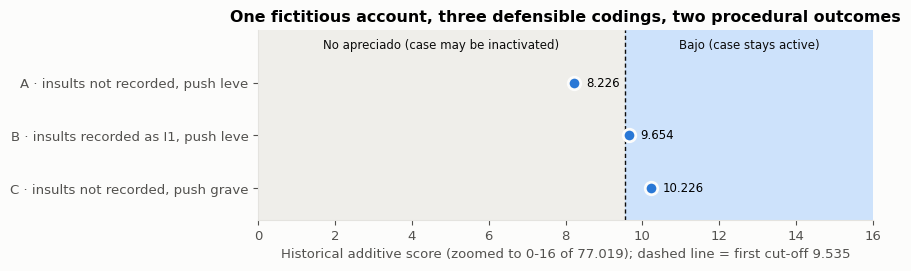

In [13]:
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.axvspan(0, 9.535, color='#efeeea', lw=0); ax.axvspan(9.535, 16, color=RAMP[0], lw=0)
ax.axvline(9.535, color=INK, lw=1, ls=(0, (3, 2)))
ax.text(4.77, 2.65, 'No apreciado (case may be inactivated)', ha='center', fontsize=8.5, color=INK)
ax.text(12.77, 2.65, 'Bajo (case stays active)', ha='center', fontsize=8.5, color=INK)
short = ['A · insults not recorded, push leve', 'B · insults recorded as I1, push leve', 'C · insults not recorded, push grave']
for k, (label, codes) in enumerate(versions):
    x = float(evaluate(make_case(*codes))['score_exact'])
    ax.plot([x], [2 - k], 'o', color=BLUE, ms=9, mec=SURF, mew=2)
    ax.text(x + 0.3, 2 - k, f'{x:.3f}', va='center', fontsize=8.5)
ax.set_yticks([2, 1, 0]); ax.set_yticklabels(short); ax.grid(False)
ax.set_xlim(0, 16); ax.set_ylim(-0.6, 3.0)
ax.set_xlabel('Historical additive score (zoomed to 0-16 of 77.019); dashed line = first cut-off 9.535')
ax.set_title('One fictitious account, three defensible codings, two procedural outcomes')
plt.tight_layout(); plt.show()

### 9 · Bridge to VioGén 2, without overclaiming

What this module can support is a **comparison of rule structures**, not of numbers:

* The **upward-only override** documented for 2016 (rule 1.5) is still the pattern in Instrucción 1/2025, §§ 3.8 and 6.2, as read in Module 1. The *direction* of officer discretion over the automatic level has not changed.
* The **"no apreciado" level**, and with it the discretionary inactivation of rule 1.6, was removed with VioGén 2 (in force 30 June 2025). Module 1 shows those cases absorbed into *bajo*.
* The **weights, items and cut-offs** of VPR5.0-H (2019) and of VioGén 2 are not public. Nothing in sections 3–8 may be used to explain, estimate or reproduce a 2025–2026 classification, a Module 1 trend, or any police decision.

The historical model is useful because it is the only version whose arithmetic is public. It shows **the kinds of choices** an actuarial police form requires (what counts, how much, where the lines go, who may move a case across them). It does not show which choices are made today.

### 10 · Optional: build your own fictitious form

Requires `ipywidgets` (preinstalled in Colab). Rows ticked under *Sí* are added (their parent question is set to *Sí*); rows under *No se sabe* stay unknown; every other row is *No*. The full app with tri-state answers per row is `interactive_app.py` (Streamlit).

In [14]:
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    options = [(f"{it.indicator or it.factor} · {it.english} [{it.weight}]", it.code) for it in ITEMS]
    yes_box = widgets.SelectMultiple(options=options, rows=12, description='Sí', layout=widgets.Layout(width='95%'))
    unk_box = widgets.SelectMultiple(options=options, rows=6, description='No se sabe', layout=widgets.Layout(width='95%'))
    out = widgets.Output()
    def update(*_):
        with out:
            clear_output(wait=True)
            try:
                e = evaluate(make_case(*yes_box.value, unknown=[c for c in unk_box.value if c not in yes_box.value]))
            except ValueError as err:
                print('Inconsistent form:', err); return
            if e['complete']:
                print(f"Score {e['score_exact']} / 77.019 -> {e['category']} ({e['category_es']}). Historical VPR4.0, not VioGén 2.")
            else:
                print(f"Score between {e['score_min']:.3f} and {e['score_max']:.3f}: level {e['category_at_min']} to {e['category_at_max']}.")
            print('Who decided? Input: which rows you ticked. Design: their weights and the cut-offs. Procedure: what follows.')
    yes_box.observe(update, names='value'); unk_box.observe(update, names='value')
    display(widgets.VBox([yes_box, unk_box, out])); update()
except ImportError:
    print('ipywidgets is not installed: pip install ipywidgets, or run: streamlit run interactive_app.py')

### 11 · What we can and cannot conclude

**Supported by the source and the computation**
1. VPR4.0 was an additive actuarial form: 63 rows, 32 with weight, total 77.019, five levels cut at 9.535 / 21.886 / 34.715 / 45.284 (pp. 192–194, 274–275).
2. Much of what is decisive was set by **designers**: 13 expert weights doubled, 31 recorded rows at zero, cut-offs chosen partly for police workload.
3. **Officers** shape the input: severity choices, classification of insults, inferred items, unknowns. One severity box can move a form across the first cut-off.
4. The **procedure** fixed the direction of officer discretion over the automatic level (upwards only) and made "no apreciado" the only level at which officers could inactivate a case at their discretion (rule 1.6).
5. Under the documented rule, a form can hold 25 of 39 indicators and score "no apreciado", and 9 indicators can be enough for "extremo".

**Not supported**
* That these numbers are VioGén 2, VPR5.0-H, or the deployed software (unknown handling, boundary rule, later re-weighting).
* Anything about predictive accuracy, about fairness, or about the danger in any real situation. The weights are odds ratios for a **new police report within four months** in a 2015–2016 cohort (p. 191).
* Any explanation of Module 1's 2018–2026 series or of a police decision.

**Discussion questions**
1. Who is accountable when the first cut-off was set to limit false negatives *and* to keep caseloads "asumibles"?
2. Rule 1.5 lets officers raise but never lower the level. Does that constrain discretion, or move it to the input layer?
3. Should a recorded fact that weighs zero be shown to the officer, the victim or the judge as part of the result?